![img](https://github.com/JuliaLang/julia/raw/master/doc/src/assets/logo.svg)![img](https://avatars.githubusercontent.com/u/7346142?s=200&v=4)

# 1. Setup

In julia, we use environments to define a package setup for a specific projects. Without an environment, we risk competing dependencies between different projects. This folder contains a `Project.toml` and a `Manifest.toml`, which together define a Julia project environment. `Pkg.activate(@__DIR__)` makes this environment active instead of your global one (`@__DIR__` is the directory containing the notebook). Everyone then works with the same package versions, and nothing installed here changes your global environment. The `Pkg.add` call below records its packages in this `Project.toml`. Activation lasts for the current Julia session, so the cell has to be rerun after a kernel restart.

In [1]:
using Pkg
Pkg.activate(@__DIR__)

  Activating project at `c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions`


In [2]:
Pkg.add(["BenchmarkTools", "LinearAlgebra", "KernelAbstractions", "Plots", "CUDA"]) #replace CUDA by AMDGPU or Metal for other backends

    Updating registry at `C:\Users\evely\.julia\registries\General.toml`
   Resolving package versions...
     Project No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
    Manifest No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Manifest.toml`


In [3]:
using BenchmarkTools, LinearAlgebra, KernelAbstractions, Plots, CUDA

In [4]:
Pkg.status()

Status `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
⌃ [21141c5a] AMDGPU v2.10.0
  [6e4b80f9] BenchmarkTools v1.8.0
  [052768ef] CUDA v6.5.0
  [7073ff75] IJulia v1.34.4
  [63c18a36] KernelAbstractions v0.10.4
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [37e2e46d] LinearAlgebra v1.12.0
Info Packages marked with ⌃ have new versions available and may be upgradable.


## 1.1. Selecting a backend

Each vendor has its own Julia package (CUDA.jl, AMDGPU.jl, Metal.jl) containing the compiler and runtime for its hardware. CUDA.jl, for instance, needs only a working NVIDIA driver and downloads a CUDA toolkit if none is installed. KernelAbstractions builds on these packages, so the same kernel runs on whichever `Backend` is selected below, including the CPU.

In [5]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :NVIDIA

if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

CUDABackend(false, false, false)

# 2. Vector addition

We start with elementwise vector addition, $\vec{c} = \vec{a} + \vec{b}$. Let's allocate and initialize the vectors.

In [6]:
# inputs a, b and output c in host memory
vector_size = 1024
a = rand(1:4, vector_size)
b = rand(1:4, vector_size)
c = zeros(Int, vector_size)

a

1024-element Vector{Int64}:
 1
 3
 3
 4
 4
 2
 3
 4
 3
 1
 1
 3
 3
 ⋮
 2
 3
 1
 2
 1
 3
 2
 4
 2
 1
 3
 3

## 2.1. CPU vector addition

Julia can form the sum in two ways. **`c = a + b`** allocates a **new** vector and returns it (the old binding for `c` is replaced). **`c .= a .+ b`** writes into the **existing** storage of `c` and does not allocate a new vector for the result.

In [8]:
c = a + b
c

1024-element Vector{Int64}:
 5
 6
 6
 8
 7
 3
 6
 8
 7
 3
 5
 4
 6
 ⋮
 5
 5
 2
 3
 4
 5
 6
 5
 3
 2
 4
 4

In [9]:
c .= a .+ b
c

1024-element Vector{Int64}:
 5
 6
 6
 8
 7
 3
 6
 8
 7
 3
 5
 4
 6
 ⋮
 5
 5
 2
 3
 4
 5
 6
 5
 3
 2
 4
 4

The next cell benchmarks both forms. In each `Trial`, **`allocs`** is the number of heap allocations per call (`a + b` allocates a new vector every time; `c .= a .+ b` reuses `c`). You should see more allocations and often more garbage-collection time for `a + b`, because Julia must reserve fresh storage for the result on every call even though the elementwise addition is the same. Timing and allocation both matter on the GPU, where we pre-allocate `dc` instead of repeating `dc = da + db` in a loop.

In [11]:
t_alloc = @benchmark a + b
t_inplace = @benchmark (c .= a .+ b)

println("heap allocations per call: a + b → ", t_alloc.allocs, ",  c .= a .+ b → ", t_inplace.allocs)
display(t_alloc)
display(t_inplace)

heap allocations per call: a + b → 3,  c .= a .+ b → 1


BenchmarkTools.Trial: 10000 samples with 207 evaluations per sample.
 Range (min … max):  394.203 ns … 29.270 μs  ┊ GC (min … max):  0.00% … 97.10%
 Time  (median):     793.720 ns              ┊ GC (median):     0.00%
 Time  (mean ± σ):     1.213 μs ±  1.940 μs  ┊ GC (mean ± σ):  32.35% ± 18.48%

  ▁██▅▄▂▁                                                      ▂
  ████████▇▇▆▆▅▅▅▅▄▁▁▃▁▃▁▁▁▁▃▁▁▁▁▁▁▁▁▃▁▃▁▃▄▁▁▁▅▇████▇▇▆▇▇▇▇▇▇▇ █
  394 ns        Histogram: log(frequency) by time      10.7 μs <

 Memory estimate: 8.09 KiB, allocs estimate: 3.

BenchmarkTools.Trial: 10000 samples with 919 evaluations per sample.
 Range (min … max):  105.550 ns …  29.067 μs  ┊ GC (min … max): 0.00% … 99.44%
 Time  (median):     124.157 ns               ┊ GC (median):    0.00%
 Time  (mean ± σ):   131.055 ns ± 293.274 ns  ┊ GC (mean ± σ):  2.21% ±  0.99%

      ▇▇▂ ▁█▇▅▂                                                  
  ▂▂▁▂███▇█████▇▅▄▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▂▂▂▂▂▂▂▂▂▂▂▂ ▃
  106 ns           Histogram: frequency by time          224 ns <

 Memory estimate: 32 bytes, allocs estimate: 1.

## 2.2. GPU arrays and array operations

To do the same on the GPU, we first allocate device arrays and copy the inputs over. The addition writes into pre-allocated `dc`, as `c .= a .+ b` did on the CPU in §2.1—not `dc = da + db`, which would allocate a new device vector every time.

In [13]:
# allocate reserves uninitialized device memory; copyto! copies host data into it

da = allocate(Backend, eltype(a), size(a)...)
copyto!(da, a)
db = allocate(Backend, eltype(b), size(b)...)
copyto!(db, b)

# KernelAbstractions.zeros allocates a zero-initialized device array
dc = KernelAbstractions.zeros(Backend, Int, size(a)...)

# displaying a device array copies it to the host; note the array type
da

1024-element CuArray{Int64, 1, CUDACore.DeviceMemory}:
 1
 3
 3
 4
 4
 2
 3
 4
 3
 1
 1
 3
 3
 ⋮
 2
 3
 1
 2
 1
 3
 2
 4
 2
 1
 3
 3

`+` works on device arrays as well, on every backend: (Note that we refer to GPU as device and CPU as host.)

In [14]:
dc .= da .+ db


1024-element CuArray{Int64, 1, CUDACore.DeviceMemory}:
 5
 6
 6
 8
 7
 3
 6
 8
 7
 3
 5
 4
 6
 ⋮
 5
 5
 2
 3
 4
 5
 6
 5
 3
 2
 4
 4

## 2.3. Scaling of `+`

Elementwise addition on the CPU (`c .= a .+ b`) and on the device (`dc .= da .+ db`) launch the same kind of work. On the device the call returns once the work has been sent to the GPU, not when the addition has finished. The next cell times `dc .= da .+ db` twice: once as the call stands, and once followed by `KernelAbstractions.synchronize`, which blocks the host until the device is done.

In [15]:
# submission only: returns before the GPU is done
@btime $dc .= $da .+ $db

# submission + wait: the time until the addition has finished
@btime begin
    $dc .= $da .+ $db
    KernelAbstractions.synchronize($Backend)
end

  2.675 μs (8 allocations: 320 bytes)
  13.600 μs (9 allocations: 336 bytes)


Only the second measurement includes the addition. For this vector of 1024 elements both numbers are mostly the cost of sending the work.

The next cell repeats that synchronized device measurement and `z .= x .+ y` on the CPU at lengths `2^3`, `2^5`, …, `2^21`. Each iteration builds fresh host vectors `x` and `y` with `rand` on the **CPU**, and **allocates** device arrays and **copies** the host data into them.

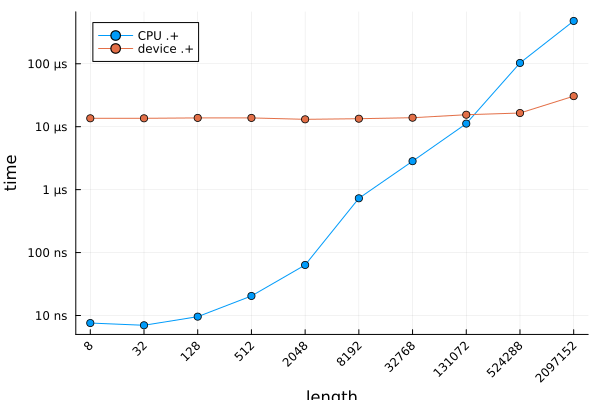

In [ ]:
sizes = 2 .^ (3:2:21)
t_cpu_plus= []
t_dev_plus = []
for n in sizes
    x, y = rand(Float32, n), rand(Float32, n)
    z = similar(x)
    push!(t_cpu_plus, @belapsed $z .= $x .+ $y)
    dx = allocate(Backend, Float32, n)
    copyto!(dx, x)
    dy = allocate(Backend, Float32, n)
    copyto!(dy, y)
    dz = KernelAbstractions.zeros(Backend, Float32, n)
    push!(t_dev_plus, @belapsed begin
        $dz .= $dx .+ $dy
        KernelAbstractions.synchronize($Backend)
    end)
end

tlabel(v) = begin
    x, u = v < 1e-6 ? (v * 1e9, "ns") : v < 1e-3 ? (v * 1e6, "µs") : v < 1 ? (v * 1e3, "ms") : (v, "s")
    r = round(x; sigdigits = 2)
    string(isinteger(r) ? Int(r) : r, " ", u)
end

Plots.plot(sizes, Float64.([t_cpu_plus t_dev_plus]);
    label = ["CPU .+" "device .+"],
    xlabel = "length", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)), xrotation = 45,
    yformatter = tlabel, marker = :circle, legend = :topleft)

On the left of the figure the device time barely changes with length. Launching the broadcast costs as much as the addition, so device `.+` is slower than CPU `.+`. Once the vector is long enough that the addition dominates the launch, device `.+` is faster, and the advantage grows with the length.

![CPU versus GPU: a few large cores with control and cache on the left, a wide grid of small arithmetic units on the right](img/CPUvsGPU.png)

A CPU (left) has a few powerful cores. Most of its area goes to control logic and cache, with comparatively few arithmetic units (green). It is designed for low latency on a small number of complex instruction streams, such as the serial loop behind `c .= a .+ b`.

A GPU (right) devotes that area to many simple arithmetic units. It is designed for throughput, applying the same instruction to many data elements at once. Device `+` has this structure: one addition per element, across those units.

## 2.4. Host loops over device arrays

`da`, `db`, and `dc` now live in GPU memory. What happens if the host indexes them one element at a time?

In [17]:
try
    for i in eachindex(dc)
        dc[i] = da[i] + db[i]
    end
catch e
    showerror(stdout, e)
end

┌ Warning: Performing scalar indexing on task Task (runnable, started) @0x0000027a5b6aa590.
│ Invocation of getindex resulted in scalar indexing of a GPU array.
│ This is typically caused by calling an iterating implementation of a method.
│ Such implementations *do not* execute on the GPU, but very slowly on the CPU,
│ and therefore should be avoided.
│ 
│ If you want to allow scalar iteration, use `allowscalar` or `@allowscalar`
│ to enable scalar iteration globally or for the operations in question.
└ @ GPUArraysCore C:\Users\evely\.julia\packages\GPUArraysCore\AR5EZ\src\GPUArraysCore.jl:145


The loop fails with a *scalar indexing* error. It runs on the host, so every `da[i]`, `db[i]`, and `dc[i]` would be a separate, synchronous transfer between device and host memory: about 3000 transfers for 1024 elements. The result would be correct but very slow, so GPU array packages disallow scalar indexing by default. (With `DEV = :CPU`, `da` is an ordinary `Array` and the loop runs.)

`dc .= da .+ db` in §2.2 works because multiple dispatch selects a GPU broadcast that launches a kernel into pre-allocated storage. The same holds for `da + db`, `sum`, `maximum`, `map`, and `reduce` on device arrays.

To run our own loop on the device, we write a **kernel**: a function executed on the GPU, with all reads and writes in device memory. Custom kernels are needed when a computation cannot be expressed with the built-in array operations, but whenever possible you should use built-in operations as those will be faster. The purpose of this tutorial is just educational: to familiarize yourself with how a GPU works.

## 2.5. Writing your first kernel

Instead of one loop that visits every element, a kernel describes what a single loop iteration does, and the GPU runs many instances of it concurrently. Each instance is called a work item (a *thread* in CUDA terminology), and work items are grouped into workgroups (CUDA: *thread blocks*).

One step of `c .= a .+ b`, as a KernelAbstractions kernel:

In [18]:
@kernel function vadd_kernel!(c, a, b)
    i = @index(Local)
    c[i] = a[i] + b[i]
end

vadd_kernel! (generic function with 4 methods)

`@kernel` marks the function as a kernel, i.e. the code executed by one work item. `@index(Local)` returns the index of the work item within its workgroup, starting at 1. Since we launch a single workgroup covering the whole vector, this is also the element index; section 2.6 shows why that breaks down for longer vectors. Kernels do not return values; they write their results into an array argument, here `c`.

A launch takes two steps. First the kernel is instantiated for a backend and a workgroup size, the number of work items per workgroup. This does not run anything yet:

In [19]:
kernel! = vadd_kernel!(Backend, length(da))

KernelAbstractions.Kernel{CUDABackend, KernelAbstractions.NDIteration.StaticSize{(1024,)}, KernelAbstractions.NDIteration.DynamicSize, typeof(gpu_vadd_kernel!)}(CUDABackend(false, false, false), Main.gpu_vadd_kernel!)

Then it is called with its arguments and an `ndrange`, the total number of work items:

In [20]:
kernel!(dc, da, db, ndrange=length(da))

A kernel launch, like `dc .= da .+ db`, returns once the work has been submitted. `KernelAbstractions.synchronize(Backend)` is the same wait as in the timings of section 2.3, and we call it here before reading the result. This is different from `@synchronize`, which appears later inside kernels and makes the work items of a workgroup wait for one another.

In [21]:
KernelAbstractions.synchronize(Backend)

# copy the result back to the CPU and compare with the CPU answer
Array(dc) == a + b

true

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 1: SAXPY

SAXPY (single-precision *a x plus y*) is the BLAS level-1 operation `y = α * x + y`. Write `saxpy_kernel!` in the style of `vadd_kernel!`, with one work item per element and `@index(Local)`, since we again launch a single workgroup. Note that `y` is both input and output.

Write one line of code at each `# TODO` in both cells. The second cell copies `x` and `y` to the device; you build the launcher, launch it, and synchronize. It should print `true`. A solution is in `proposed-solution/exercise_1_saxpy.ipynb`.

</div>

In [22]:
@kernel function saxpy_kernel!(y, α, x)
    # TODO 1: this work item's index i from @index(Local)

    # TODO 2: SAXPY update at index i

end

saxpy_kernel! (generic function with 4 methods)

In [23]:
α = 2.0f0
x = rand(Float32, 1024)
y = rand(Float32, 1024)

dx = allocate(Backend, Float32, length(x))
copyto!(dx, x)
dy = allocate(Backend, Float32, length(y))
copyto!(dy, y)

# TODO 3: build saxpy! for one workgroup of length 1024

# TODO 4: launch saxpy! on dy, α, and dx

KernelAbstractions.synchronize(Backend)

Array(dy) ≈ α .* x .+ y

false

## 2.6. Execution hierarchy and global indexing

![GPU execution hierarchy: threads inside a thread block with shared memory, blocks gathered into clusters, and a grid over global memory](img/threadsGPU.png)

A kernel launch is organized in three levels, which KernelAbstractions and CUDA name differently:

| KernelAbstractions | NVIDIA / CUDA | Runs on | Memory at this level |
|---|---|---|---|
| work item | thread | one SIMD lane; lanes execute in groups of 32 (*warps*) | private registers |
| workgroup | thread block | one streaming multiprocessor (SM) | shared memory, visible to the workgroup |
| all work items (`ndrange`) | grid | the whole GPU | global memory, visible to all work items |

A workgroup always runs on a single SM (small hardware processor); a GPU has many SMs, but a workgroup is never split across them. Shared memory sits on the SM next to the arithmetic units and lets the work items of a workgroup exchange data quickly. `vadd_kernel!` has no use for it, since each work item touches only its own element; the matrix multiplication notebook does. Global memory, where `da`, `db`, and `dc` live, is visible to every work item but much slower.

The middle of the picture shows thread block clusters; we do not use them here.

Our first launch put all 1024 work items into one workgroup, which runs on one SM. What happens if the vector is ten times longer and we launch it the same way?

In [24]:
vector_size = 10240
a = rand(1:4, vector_size)
b = rand(1:4, vector_size)

da = allocate(Backend, eltype(a), size(a)...)
copyto!(da, a)
db = allocate(Backend, eltype(b), size(b)...)
copyto!(db, b)
dc = KernelAbstractions.zeros(Backend, Int, vector_size)

# one workgroup of 10240 work items
kernel! = vadd_kernel!(Backend, length(da))
try
    kernel!(dc, da, db, ndrange=length(da))
catch e
    showerror(stdout, e)
end

ArgumentError: Work-group size (10240, 1, 1) exceeds the maximum of (1024, 1024, 64) per dimension

This launch fails: the hardware limits the size of a workgroup, to 1024 work items on current NVIDIA and AMD GPUs. (The CPU backend's limit is larger, 4096 on our test machine, but still below 10240.)

In [25]:
max_workgroupsize = 1024

1024

The fix is to split the work into ten workgroups of 1024 (`cld(10240, 1024) = 10`), which the GPU distributes over its SMs. `@index(Local)` is then no longer sufficient: it restarts at 1 in every workgroup, so all ten workgroups would write to `c[1:1024]`. The index has to count across workgroups,

`i = @index(Local) + (@index(Group) - 1) * workgroupsize`,

where `@index(Group)` is the number of the workgroup (1 to 10) and `(@index(Group) - 1) * workgroupsize` is the number of elements covered by the preceding workgroups. KernelAbstractions provides this index directly as `@index(Global)`. With a single workgroup, `@index(Global)` and `@index(Local)` coincide, which is why the first kernel was correct.

In [26]:
@kernel function vadd_kernel!(c, a, b)
    i = @index(Global)
    if i <= length(c)
        c[i] = a[i] + b[i]
    end
end

The `if` excludes work items beyond the end of the vector. 10240 divides evenly into workgroups of 1024, but a length such as 10000 would leave the last workgroup partly empty. KernelAbstractions already skips those work items; the check makes the assumption explicit.

We now launch with workgroups of 1024. `ndrange` still covers all 10240 elements, so KernelAbstractions creates ten workgroups:

In [27]:
kernel! = vadd_kernel!(Backend, max_workgroupsize)
kernel!(dc, da, db, ndrange=length(da))
KernelAbstractions.synchronize(Backend)

Array(dc) == a + b

true

## 2.7. Timing `vadd_kernel!`

`vadd_kernel!` now uses `@index(Global)`, with a workgroup of at most `max_workgroupsize` and `ndrange` equal to the vector length, so the whole vector is covered at every length in the sweep, including those past 1024. The timings from section 2.3 are still in `t_cpu_plus` and `t_dev_plus`. The next cell times this kernel at the same lengths and adds it to the figure. Each device measurement waits with `synchronize`.

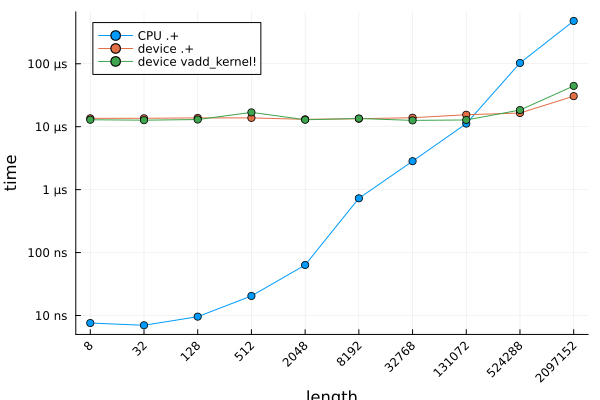

In [30]:
t_dev_vadd = []
for n in sizes
    x, y = rand(Float32, n), rand(Float32, n)
    dx = allocate(Backend, Float32, n)
    copyto!(dx, x)
    dy = allocate(Backend, Float32, n)
    copyto!(dy, y)
    w = min(n, max_workgroupsize)
    dz, k! = similar(dx), vadd_kernel!(Backend, w)
    push!(t_dev_vadd, @belapsed begin
        $k!($dz, $dx, $dy; ndrange = $n)
        KernelAbstractions.synchronize($Backend)
    end)
end

Plots.plot(sizes, ([t_cpu_plus t_dev_plus t_dev_vadd]);
    label = ["CPU .+" "device .+" "device vadd_kernel!"],
    xlabel = "length", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)), xrotation = 45,
    yformatter = tlabel, marker = :circle, legend = :topleft)

`vadd_kernel!` lies next to device `.+`: both perform the same addition, and both pay for the launch. On the long vectors both pull ahead of CPU `.+`.

## 2.8. Race conditions in global memory

Work items in different workgroups run concurrently and in no guaranteed order. This is harmless as long as each work item writes its own element, as in `vadd_kernel!`. Consider instead summing a vector of 10240 ones by having every work item add its element to `s[1]`:

In [31]:
@kernel function racy_sum_kernel!(s, x)
    i = @index(Global)
    s[1] += x[i]
end

racy_sum_kernel! (generic function with 4 methods)

In [32]:
dx = KernelAbstractions.ones(Backend, Int, 10240)
ds = KernelAbstractions.zeros(Backend, Int, 1)

racy_sum! = racy_sum_kernel!(Backend, max_workgroupsize)
racy_sum!(ds, dx, ndrange=length(dx))
KernelAbstractions.synchronize(Backend)

Array(ds)[1]

1

The result should be 10240; on a GPU backend you often get a much smaller value (for example 1). The statement `s[1] += x[i]` consists of a read of `s[1]`, an addition, and a write. Many work items read `s[1]` before any of them has written it back, so they all add to the same old value and overwrite each other's results. In such a race condition the result depends on the timing of the work items. On the CPU backend the same kernel happened to return 10240, so a passing test does not show that a kernel is free of races.

Two work items should therefore never write to the same location without coordination. For a sum, the built-in function takes care of this:

In [33]:
sum(dx)

10240

Kernels can also use atomic operations, which perform the read, the addition, and the write as one indivisible step. They are correct but slow when many work items update the same location, because the updates are serialized. The best solution is to ensure every location is only written to by a single thread while no other is reading.

# 3. Summary

- A portable `Backend`; moving data with `allocate`, `copyto!`, and `KernelAbstractions.zeros`
- Why a host loop over device arrays fails, and why built-in operations such as `+` still work
- Writing and launching a kernel, and how device `.+` and `vadd_kernel!` compare with CPU `.+`
- The execution hierarchy: work items, workgroups, and streaming multiprocessors
- Indexing across workgroups with `@index(Global)`
- Race conditions in global memory

Next, **`matrix_multiplication.ipynb`** covers 2D indexing, naive and shared-memory kernels for transpose and matrix multiplication, and why memory access dominates their performance.